<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Source score with vs. without the extracellular neighbourhood context (max_k=10 vs. 1), incl. hold-out benchmark.
> - **Manuscript panels:** Reviewer response (source-score neighbourhood)
> - **Inputs:** Outputs of `source_score_neighborhood_comparison.py`
> - **Outputs:** Figures A-F in `ms_figures/xenium_msbrain_5k/source_score_neighborhood/`
> - **Environment / kernel:** `troutpy_drvi (executed with `execute_notebook10.sbatch`)`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# uRNA source score: with vs. without the extracellular neighborhood (xenium_msbrain_5k)

The production source score (`recompute_source_score_final_lambda05.py`, used in `5_computing_cell_scores_msbrain.ipynb`)
assigns each extracellular transcript to candidate parent cells within `max_dist` with weight

$$w_{c} = \underbrace{\frac{|\text{context genes} \cap \text{genes expressed by } c|}{|\text{context genes}|}}_{\text{expression match}} \cdot e^{-\lambda d_c}, \qquad \text{score}_c = \frac{w_c}{\sum_{c'} w_{c'} + \text{residual}}$$

The **context genes** come from the transcript's $k$ nearest extracellular neighbors, with $k$ growing from 1 (enrichment ≤ ambient floor)
to `max_k` (enrichment ≥ `signal_threshold`). In dense uRNA clouds the transcript therefore borrows signal from its neighbors.

| mode | `max_k` | context | everything else |
|---|---|---|---|
| **with_neighbors** (default, as presented) | 10 (adaptive) | own gene + up to 9 neighbor genes | λ=0.5, `max_dist`=200, residual=0.1, `signal_threshold`=10, same ambient floor, shell and expression matrix |
| **no_neighbors** | 1 | only the transcript's own gene | identical |

Without neighbors, a candidate's weight is $e^{-\lambda d}$ if it expresses the gene and 0 otherwise, so the best parent is simply the **closest cell that expresses the gene**.

**How we evaluate it**
1. *What changes*: how many transcripts actually use neighbors (k>1), and how often the assignment changes.
2. *Confidence*: assignment score and cell-type entropy.
3. *Plausibility*: does the predicted parent / cell type express the gene?
4. *Downstream*: per-cell source score and the per-cell-type ranking used in the paper.
5. *Ground-truth benchmark*: peripheral transcripts of 10% of cells are removed from their cell (expression and boundary rebuilt without them),
   put into the extracellular pool, and scored. Since we know the true parent, we measure parent / cell-type recovery, sweeping `max_k` ∈ {1,2,5,10,20}
   at two densities (full ring and 20% of it).
6. *Qualitative*: spatial maps of the same ROI under both modes.

Compute runs on the cluster: `source_score_neighborhood_comparison.py` / `.sbatch` in this folder.

In [1]:
import json, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad
from scipy.stats import spearmanr, pearsonr, wilcoxon

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
sns.set_style('ticks')

data_dir = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_msbrain_5k")
res_dir = data_dir / "source_score_neighborhood_comparison"
saving_path = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/source_score_neighborhood")
saving_path.mkdir(parents=True, exist_ok=True)

info = json.load(open(res_dir / "run_info.json"))
MODES = ['with_neighbors', 'no_neighbors']
MODE_LABEL = {'with_neighbors': 'with neighbors (max_k=10)', 'no_neighbors': 'no neighbors (max_k=1)'}
MODE_COL = {'with_neighbors': '#c0392b', 'no_neighbors': '#2c7fb8'}
cell_types = np.array(info['cell_types'])
cell_ids = np.array(info['cell_ids'])
print({k: info[k] for k in ['params', 'ambient_floor', 'reproduction_parent_agreement', 'reproduction_max_score_diff', 'runtime_min']})

{'params': {'max_dist': 200.0, 'lmbda': 0.5, 'max_k': 10, 'signal_threshold': 10.0, 'residual': 0.1, 'chunk_size': 100000}, 'ambient_floor': 4.192010291567437, 'reproduction_parent_agreement': 1.0, 'reproduction_max_score_diff': 0.0, 'runtime_min': 129.8574161529541}


In [2]:
real = pd.read_parquet(res_dir / "real_per_transcript.parquet")
per_cell = pd.read_csv(res_dir / "real_per_cell.csv")
gbt = {m: pd.read_csv(res_dir / f"real_gene_by_type_{m}.csv", index_col=0) for m in MODES}

table = ad.read_zarr(data_dir / "data_annotated.zarr" / "tables" / "table")
ct_cat = table.obs['cell_type'].astype('category')
ct_colors = dict(zip(ct_cat.cat.categories, table.uns['cell_type_colors']))
assert list(cell_types) == list(np.sort(ct_cat.cat.categories)), "cell type order mismatch"
print(f"{len(real):,} extracellular transcripts, {len(per_cell):,} cells")

8,388,470 extracellular transcripts, 9,185 cells


## A. What actually changes
Transcripts with `k_prod = 1` (enrichment at or below the ambient floor) use only their own gene in both modes, so their assignment is identical by construction.
Only transcripts with `k_prod > 1` can differ.

In [3]:
real['k_bin'] = pd.cut(real['k_prod'], [0, 1, 3, 6, 9, 10], labels=['1', '2-3', '4-6', '7-9', '10'])
for m in MODES:
    real[f'{m}__assigned'] = real[f'{m}__parent_row'] >= 0
real['same_parent'] = real['with_neighbors__parent_row'] == real['no_neighbors__parent_row']
both = real['with_neighbors__assigned'] & real['no_neighbors__assigned']
real['same_type'] = (real['with_neighbors__type'] == real['no_neighbors__type'])

summary_A = pd.DataFrame({
    'fraction of uRNA': real['k_bin'].value_counts(normalize=True).sort_index(),
    'assigned (with)': real.groupby('k_bin', observed=True)['with_neighbors__assigned'].mean(),
    'assigned (no)': real.groupby('k_bin', observed=True)['no_neighbors__assigned'].mean(),
    'same parent | both assigned': real[both].groupby('k_bin', observed=True)['same_parent'].mean(),
    'same top cell type | both assigned': real[both].groupby('k_bin', observed=True)['same_type'].mean(),
})
summary_A.loc['all'] = [1.0, real['with_neighbors__assigned'].mean(), real['no_neighbors__assigned'].mean(),
                        real.loc[both, 'same_parent'].mean(), real.loc[both, 'same_type'].mean()]
summary_A.to_csv(saving_path / 'A_summary_by_k.csv')
summary_A.style.format('{:.3f}')

,fraction of uRNA,assigned (with),assigned (no),same parent | both assigned,same top cell type | both assigned
k_bin,,,,,
1,0.701,0.995,0.995,1.000,1.000
2-3,0.111,1.000,0.995,0.683,0.808
4-6,0.078,1.000,0.992,0.631,0.792
7-9,0.052,1.000,0.989,0.631,0.804
10,0.057,1.000,0.985,0.641,0.815
all,1.000,0.996,0.994,0.896,0.942


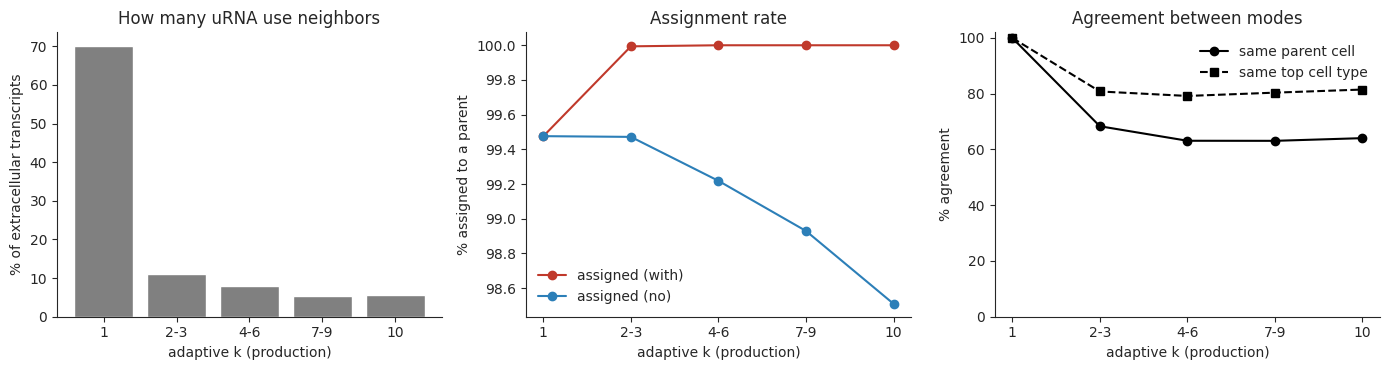

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
vc = real['k_bin'].value_counts(normalize=True).sort_index()
axes[0].bar(vc.index.astype(str), vc.values * 100, color='grey')
axes[0].set(xlabel='adaptive k (production)', ylabel='% of extracellular transcripts', title='How many uRNA use neighbors')

s = summary_A.drop('all')
for m, c in [('assigned (with)', MODE_COL['with_neighbors']), ('assigned (no)', MODE_COL['no_neighbors'])]:
    axes[1].plot(s.index.astype(str), s[m] * 100, 'o-', color=c, label=m)
axes[1].set(xlabel='adaptive k (production)', ylabel='% assigned to a parent', title='Assignment rate')
axes[1].legend(frameon=False)

axes[2].plot(s.index.astype(str), s['same parent | both assigned'] * 100, 'o-', color='k', label='same parent cell')
axes[2].plot(s.index.astype(str), s['same top cell type | both assigned'] * 100, 's--', color='k', label='same top cell type')
axes[2].set(xlabel='adaptive k (production)', ylabel='% agreement', title='Agreement between modes', ylim=(0, 102))
axes[2].legend(frameon=False)
sns.despine(); plt.tight_layout()
plt.savefig(saving_path / 'A_what_changes.pdf'); plt.show()

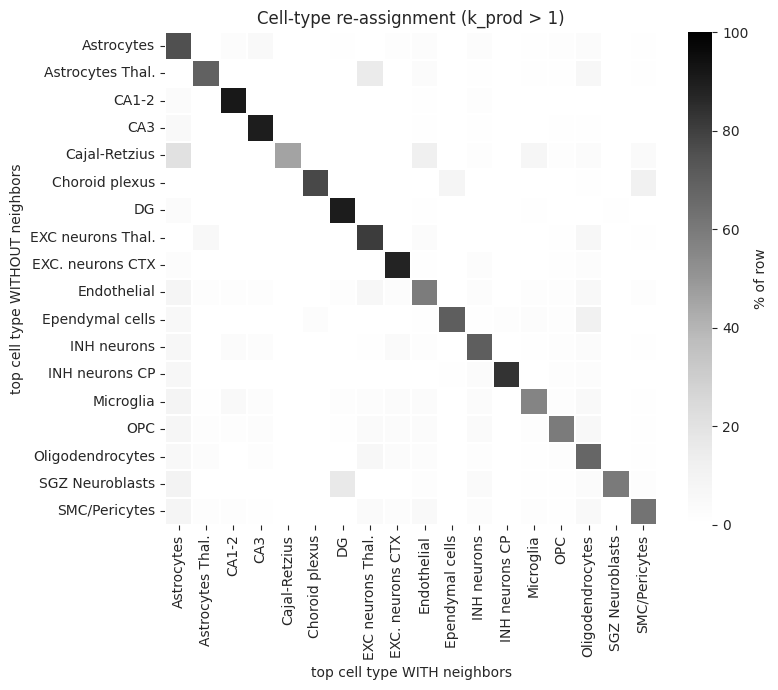

diagonal (type kept): 0.8042612312691473


In [5]:
# Where do re-assigned transcripts go? (top cell type, rows = no_neighbors, columns = with_neighbors)
sub = real[both & (real['k_prod'] > 1)]
cm = pd.crosstab(cell_types[sub['no_neighbors__type']], cell_types[sub['with_neighbors__type']])
cm = cm.reindex(index=cell_types, columns=cell_types, fill_value=0)
cmn = cm.div(cm.sum(1).replace(0, np.nan), axis=0)
plt.figure(figsize=(8, 7))
sns.heatmap(cmn * 100, cmap='Greys', vmax=100, cbar_kws={'label': '% of row'}, linewidths=0.2)
plt.xlabel('top cell type WITH neighbors'); plt.ylabel('top cell type WITHOUT neighbors')
plt.title('Cell-type re-assignment (k_prod > 1)')
plt.tight_layout(); plt.savefig(saving_path / 'A_type_confusion.pdf'); plt.show()
print('diagonal (type kept):', np.trace(cm.values) / cm.values.sum())

## B. Confidence of the assignment
`assignment score` = normalized weight of the best parent (the quantity thresholded with `min_score` in the paper's spatial plots).
`type entropy` = normalized Shannon entropy of the cell-type mass distribution (0 = all mass on one type, 1 = uniform).

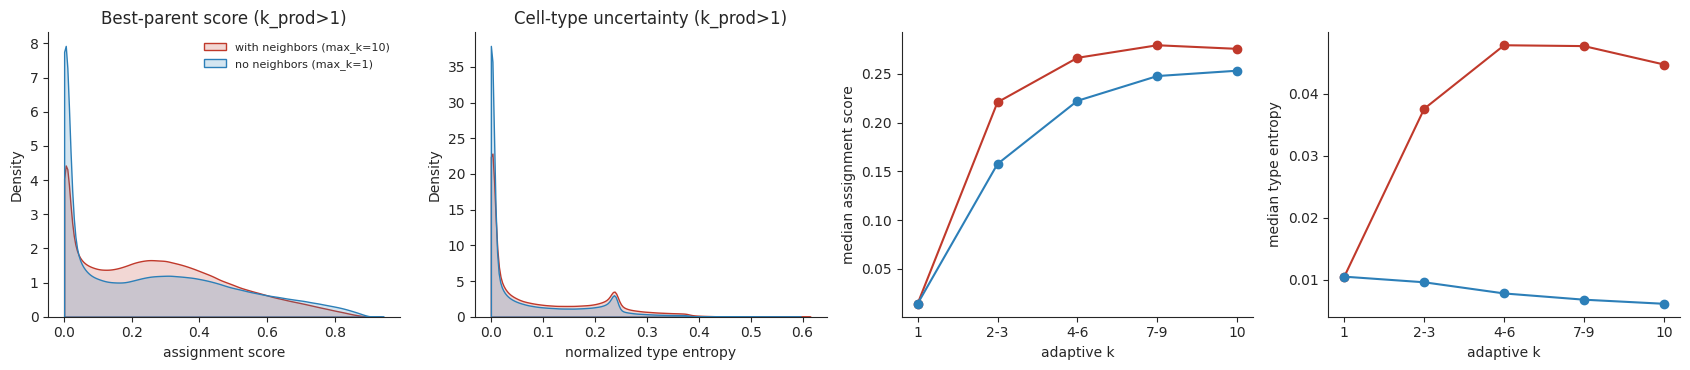

,with_neighbors,no_neighbors
median score,0.256221,0.212365
frac score >= 0.2,0.591297,0.513188
median entropy,0.043218,0.007921
median distance to parent,4.793438,6.601373


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
mask = both & (real['k_prod'] > 1)
for m in MODES:
    sns.kdeplot(real.loc[mask, f'{m}__score'], ax=axes[0], color=MODE_COL[m], label=MODE_LABEL[m], fill=True, alpha=0.2, clip=(0, 1))
    sns.kdeplot(real.loc[mask, f'{m}__entropy'], ax=axes[1], color=MODE_COL[m], fill=True, alpha=0.2, clip=(0, 1))
    g = real[both].groupby('k_bin', observed=True)
    axes[2].plot(g[f'{m}__score'].median().index.astype(str), g[f'{m}__score'].median(), 'o-', color=MODE_COL[m])
    axes[3].plot(g[f'{m}__entropy'].median().index.astype(str), g[f'{m}__entropy'].median(), 'o-', color=MODE_COL[m])
axes[0].set(xlabel='assignment score', title='Best-parent score (k_prod>1)'); axes[0].legend(frameon=False, fontsize=8)
axes[1].set(xlabel='normalized type entropy', title='Cell-type uncertainty (k_prod>1)')
axes[2].set(xlabel='adaptive k', ylabel='median assignment score')
axes[3].set(xlabel='adaptive k', ylabel='median type entropy')
sns.despine(); plt.tight_layout(); plt.savefig(saving_path / 'B_confidence.pdf'); plt.show()

conf = pd.DataFrame({m: {
    'median score': real.loc[mask, f'{m}__score'].median(),
    'frac score >= 0.2': (real.loc[mask, f'{m}__score'] >= 0.2).mean(),
    'median entropy': real.loc[mask, f'{m}__entropy'].median(),
    'median distance to parent': real.loc[mask, f'{m}__dist'].median(),
} for m in MODES})
conf

## C. Biological plausibility
Without neighbors, the predicted parent always expresses the transcript's gene (weight is 0 otherwise), so the first metric is 100% **by construction**.
With neighbors, a parent can be chosen because it matches the *neighborhood* even if it doesn't express that specific gene.
At the cell-type level we ask how common the gene is in the predicted cell type
(fraction of cells of that type expressing it) and whether the predicted type is among the top-3 expressing types for that gene.

In [7]:
Xb = (table.X != 0)
type_frac = pd.DataFrame(np.vstack([np.asarray(Xb[(ct_cat == t).values].mean(0)).ravel() for t in cell_types]),
                         index=cell_types, columns=table.var_names)          # type x gene
top3 = type_frac.rank(axis=0, ascending=False, method='min') <= 3
gidx = pd.Index(table.var_names).get_indexer(real['gene'].astype(str))
okg = gidx >= 0
for m in MODES:
    t = real[f'{m}__type'].values
    v = okg & (t >= 0)
    real[f'{m}__type_expr_frac'] = np.nan
    real.loc[v, f'{m}__type_expr_frac'] = type_frac.values[t[v], gidx[v]]
    real[f'{m}__type_in_top3'] = np.nan
    real.loc[v, f'{m}__type_in_top3'] = top3.values[t[v], gidx[v]].astype(float)

mask = both & (real['k_prod'] > 1)
plaus = pd.DataFrame({m: {
    'parent expresses gene': real.loc[mask, f'{m}__gene_expr_in_parent'].mean(),
    'mean frac of predicted-type cells expressing gene': real.loc[mask, f'{m}__type_expr_frac'].mean(),
    'predicted type in top-3 expressers of gene': real.loc[mask, f'{m}__type_in_top3'].mean(),
} for m in MODES})
plaus.to_csv(saving_path / 'C_plausibility.csv')
plaus

,with_neighbors,no_neighbors
parent expresses gene,0.685205,1.000000
mean frac of predicted-type cells expressing gene,0.541737,0.563339
predicted type in top-3 expressers of gene,0.359395,0.393198


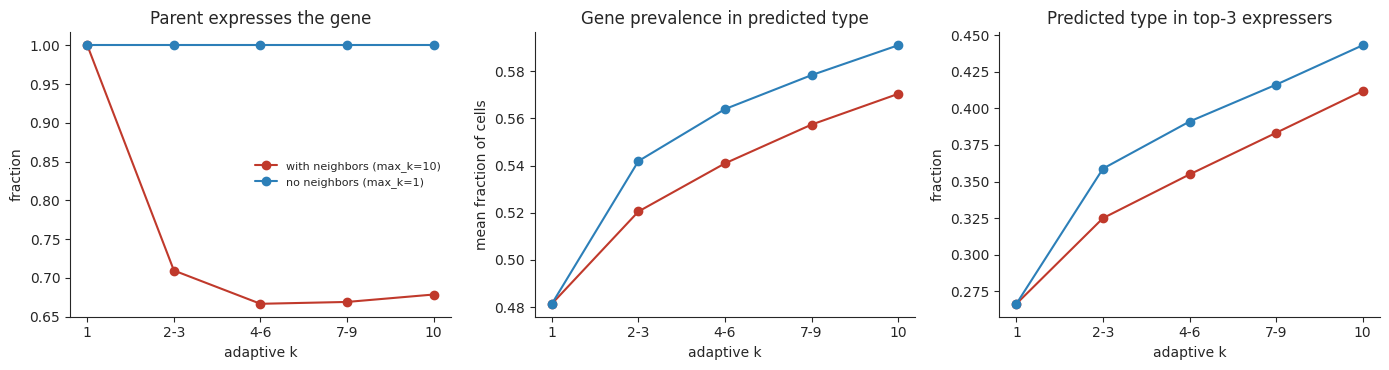

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
g = real[both].groupby('k_bin', observed=True)
for m in MODES:
    for ax, col in zip(axes, ['gene_expr_in_parent', 'type_expr_frac', 'type_in_top3']):
        y = g[f'{m}__{col}'].mean()
        ax.plot(y.index.astype(str), y.values, 'o-', color=MODE_COL[m], label=MODE_LABEL[m])
axes[0].set(title='Parent expresses the gene', ylabel='fraction', xlabel='adaptive k')
axes[1].set(title='Gene prevalence in predicted type', ylabel='mean fraction of cells', xlabel='adaptive k')
axes[2].set(title='Predicted type in top-3 expressers', ylabel='fraction', xlabel='adaptive k')
axes[0].legend(frameon=False, fontsize=8)
sns.despine(); plt.tight_layout(); plt.savefig(saving_path / 'C_plausibility_by_k.pdf'); plt.show()

## D. Downstream: per-cell and per-cell-type source scores
These are the quantities shown in the paper (`urna_source_score` on UMAP/spatial plots and the per-cell-type ranking).

per-cell source score: Spearman=0.997, Pearson=0.998
cell-type ranking (mean source score): Spearman=0.998; normalized: 0.994


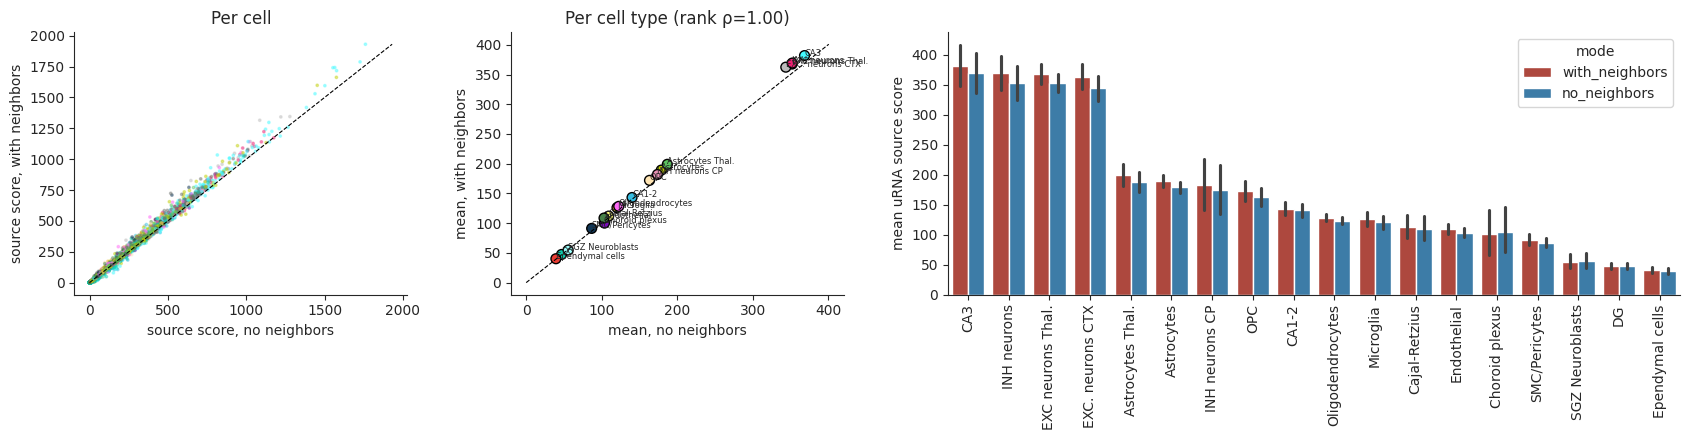

In [9]:
per_cell['cell_type'] = per_cell['cell_type'].astype(str)
per_cell['n_counts'] = table.obs['n_counts'].values
for m in MODES:
    per_cell[f'{m}__norm'] = per_cell[f'{m}__urna_source_score'] / per_cell['n_counts']

a, b = per_cell['with_neighbors__urna_source_score'], per_cell['no_neighbors__urna_source_score']
print(f"per-cell source score: Spearman={spearmanr(a, b)[0]:.3f}, Pearson={pearsonr(a, b)[0]:.3f}")

ct_mean = per_cell.groupby('cell_type')[[f'{m}__urna_source_score' for m in MODES] + [f'{m}__norm' for m in MODES]].mean()
rho_rank = spearmanr(ct_mean['with_neighbors__urna_source_score'], ct_mean['no_neighbors__urna_source_score'])[0]
rho_rank_n = spearmanr(ct_mean['with_neighbors__norm'], ct_mean['no_neighbors__norm'])[0]
print(f"cell-type ranking (mean source score): Spearman={rho_rank:.3f}; normalized: {rho_rank_n:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), gridspec_kw={'width_ratios': [1, 1, 2.2]})
axes[0].scatter(b, a, s=3, alpha=0.4, c=[ct_colors[t] for t in per_cell['cell_type']], rasterized=True)
lim = max(a.max(), b.max()); axes[0].plot([0, lim], [0, lim], 'k--', lw=0.8)
axes[0].set(xlabel='source score, no neighbors', ylabel='source score, with neighbors', title='Per cell')

axes[1].scatter(ct_mean['no_neighbors__urna_source_score'], ct_mean['with_neighbors__urna_source_score'],
                c=[ct_colors[t] for t in ct_mean.index], s=50, edgecolor='k')
lim = ct_mean[[f'{m}__urna_source_score' for m in MODES]].values.max() * 1.05
axes[1].plot([0, lim], [0, lim], 'k--', lw=0.8)
for t, r in ct_mean.iterrows():
    axes[1].annotate(t, (r['no_neighbors__urna_source_score'], r['with_neighbors__urna_source_score']), fontsize=6)
axes[1].set(xlabel='mean, no neighbors', ylabel='mean, with neighbors', title=f'Per cell type (rank ρ={rho_rank:.2f})')

order = ct_mean.sort_values('with_neighbors__urna_source_score', ascending=False).index
long = per_cell.melt(id_vars='cell_type', value_vars=[f'{m}__urna_source_score' for m in MODES], var_name='mode', value_name='score')
long['mode'] = long['mode'].str.replace('__urna_source_score', '')
sns.barplot(long, x='cell_type', y='score', hue='mode', order=order, palette=MODE_COL, ax=axes[2], errorbar=('ci', 95))
axes[2].tick_params(axis='x', rotation=90); axes[2].set(xlabel='', ylabel='mean uRNA source score')
sns.despine(); plt.tight_layout(); plt.savefig(saving_path / 'D_downstream_scores.pdf'); plt.show()

In [10]:
# Gene-level attribution: for each gene, cosine similarity between its cell-type attribution vectors in the two modes
G = gbt['with_neighbors'].reindex(columns=cell_types); H = gbt['no_neighbors'].reindex(index=G.index, columns=cell_types)
num = (G.values * H.values).sum(1); den = np.linalg.norm(G.values, axis=1) * np.linalg.norm(H.values, axis=1)
gene_cos = pd.Series(num / np.where(den > 0, den, np.nan), index=G.index)
n_per_gene = real['gene'].value_counts().reindex(G.index)
print(f"median per-gene cosine similarity of type attribution: {gene_cos.median():.3f}  (genes with >=100 uRNA: {gene_cos[n_per_gene >= 100].median():.3f})")
print('Genes whose attribution changes most (>=100 uRNA):')
display(pd.DataFrame({'cosine': gene_cos, 'n_uRNA': n_per_gene})[n_per_gene >= 100].sort_values('cosine').head(15))

# Overall type attribution of uRNA (share of total mass per cell type)
share = pd.DataFrame({m: gbt[m].sum(0) / gbt[m].values.sum() for m in MODES}).reindex(cell_types)
share['diff (with - no), pp'] = (share['with_neighbors'] - share['no_neighbors']) * 100
share.sort_values('diff (with - no), pp').style.format('{:.3f}')

median per-gene cosine similarity of type attribution: 0.969  (genes with >=100 uRNA: 0.988)
Genes whose attribution changes most (>=100 uRNA):


,cosine,n_uRNA
Tdgf1,0.042583,113.0
Esrrb,0.105396,189.0
Nmu,0.140367,124.0
Selenov,0.173464,135.0
Cxcr1,0.229990,106.0
Hcrt,0.236554,105.0
Arg1,0.352080,104.0
Il2,0.357241,155.0
Rad50,0.358500,243.0
Hoxa9,0.383520,124.0


,with_neighbors,no_neighbors,"diff (with - no), pp"
EXC neurons Thal.,0.108,0.110,-0.227
Oligodendrocytes,0.112,0.113,-0.109
INH neurons,0.061,0.061,-0.060
Astrocytes,0.138,0.138,-0.035
Cajal-Retzius,0.003,0.003,-0.014
Choroid plexus,0.003,0.003,-0.008
INH neurons CP,0.004,0.004,-0.002
Ependymal cells,0.010,0.010,0.001
Microglia,0.026,0.026,0.002
SGZ Neuroblasts,0.008,0.008,0.003


## E. Ground-truth benchmark (peripheral hold-out)
For 10% of cells (3 random seeds), the outer 30% of their transcripts are removed from the cell, the cell's expression and
boundary shell are rebuilt without them, and the held-out transcripts are inserted into the real extracellular pool
(so their neighborhoods mix with real uRNA). `density=0.2` keeps only 20% of the held-out ring (a sparser cloud).
Baseline: assign to the **nearest** cell (no expression information at all).

Two expression settings:
* **truncated** (realistic): the true cell's expression profile is rebuilt *without* the held-out ring, so genes detected only in the
  periphery are no longer "expressed" by that cell (this is what happens to real uRNA: X counts only what is inside the mask).
* **intact**: the true cell keeps its full expression profile; only positions/boundary change. This isolates the effect of the
  spatial neighborhood from the effect of genes missing from the cell's profile.

*Hard* queries are those where the nearest cell is **not** the true parent; this is where expression context has to do the work.

In [11]:
bench = pd.concat([pd.read_parquet(p) for p in sorted(res_dir.glob('benchmark_seed*_dens*.parquet'))], ignore_index=True)
KS = info['bench']['max_k']
bench['hard'] = bench['nearest_row'] != bench['true_row']
bench['nearest_correct'] = ~bench['hard']
for k in KS:
    bench[f'k{k}__parent_ok'] = bench[f'k{k}__parent_row'] == bench['true_row']
    bench[f'k{k}__type_ok'] = bench[f'k{k}__type'] == bench['true_type']
print(bench.groupby(['expr_mode', 'density', 'seed']).size().unstack())
print('fraction hard:', bench.groupby('density')['hard'].mean().round(3).to_dict())
print('k_prod distribution of held-out queries:', bench['k_prod'].value_counts(normalize=True).sort_index().round(3).to_dict())

seed                    0       1       2
expr_mode density                        
intact    0.2       94451   89931   90107
          1.0      472033  451281  452051
truncated 0.2       94451   89931   90107
          1.0      472033  451281  452051
fraction hard: {0.2: 0.307, 1.0: 0.308}
k_prod distribution of held-out queries: {1: 0.088, 2: 0.042, 3: 0.056, 4: 0.071, 6: 0.084, 7: 0.092, 8: 0.095, 10: 0.472}


In [12]:
rows = []
for (em, dens, seed, hard), g in bench.groupby(['expr_mode', 'density', 'seed', 'hard']):
    for k in KS:
        rows.append(dict(expr_mode=em, density=dens, seed=seed, subset='hard' if hard else 'easy', max_k=k,
                         parent_acc=g[f'k{k}__parent_ok'].mean(), type_acc=g[f'k{k}__type_ok'].mean(),
                         true_type_mass=g[f'k{k}__true_type_frac'].mean()))
for (em, dens, seed), g in bench.groupby(['expr_mode', 'density', 'seed']):
    for k in KS:
        rows.append(dict(expr_mode=em, density=dens, seed=seed, subset='all', max_k=k,
                         parent_acc=g[f'k{k}__parent_ok'].mean(), type_acc=g[f'k{k}__type_ok'].mean(),
                         true_type_mass=g[f'k{k}__true_type_frac'].mean()))
acc = pd.DataFrame(rows)
nearest = bench[bench.expr_mode == 'truncated'].groupby(['density', 'seed'])['nearest_correct'].mean().groupby('density').mean()
acc.to_csv(saving_path / 'E_benchmark_accuracy.csv', index=False)
acc_mean = acc.groupby(['expr_mode', 'density', 'subset', 'max_k'])[['parent_acc', 'type_acc', 'true_type_mass']].agg(['mean', 'std'])
acc_mean.round(4)

parent_acc         type_acc          \
                                     mean     std     mean     std   
expr_mode density subset max_k                                       
intact    0.2     all    1         0.7119  0.0125   0.9226  0.0018   
                         2         0.7453  0.0133   0.9423  0.0020   
                         5         0.7859  0.0131   0.9625  0.0017   
                         10        0.7923  0.0135   0.9654  0.0017   
                         20        0.7910  0.0141   0.9657  0.0014   
                  easy   1         0.9018  0.0016   0.9464  0.0010   
                         2         0.9376  0.0010   0.9670  0.0012   
                         5         0.9789  0.0008   0.9887  0.0007   
                         10        0.9871  0.0010   0.9920  0.0007   
                         20        0.9893  0.0007   0.9927  0.0010   
                  hard   1         0.2830  0.0106   0.8689  0.0025   
                         2         0.3114  0.0117   0.8863  0.0014   
                         5         0.3501  0.0132   0.9032  0.0014   
                         10        0.3528  0.0138   0.9052  0.0013   
                         20        0.3436  0.0157   0.9049  0.0004   
          1.0     all    1         0.7104  0.0113   0.9226  0.0013   
                         2         0.7445  0.0121   0.9420  0.0013   
                         5         0.7861  0.0128   0.9633  0.0017   
                         10        0.7953  0.0131   0.9666  0.0019   
                         20        0.7982  0.0132   0.9673  0.0018   
                  easy   1         0.9020  0.0009   0.9464  0.0005   
                         2         0.9377  0.0007   0.9669  0.0005   
                         5         0.9799  0.0008   0.9893  0.0004   
                         10        0.9891  0.0006   0.9927  0.0004   
                         20        0.9921  0.0006   0.9933  0.0005   
                  hard   1         0.2793  0.0077   0.8690  0.0014   
                         2         0.3094  0.0098   0.8860  0.0008   
                         5         0.3498  0.0129   0.9048  0.0020   
                         10        0.3591  0.0124   0.9081  0.0020   
                         20        0.3620  0.0122   0.9088  0.0020   
truncated 0.2     all    1         0.3669  0.0046   0.7783  0.0030   
                         2         0.4239  0.0071   0.8109  0.0028   
                         5         0.5271  0.0099   0.8711  0.0025   
                         10        0.5607  0.0124   0.8915  0.0020   
                         20        0.5757  0.0139   0.9008  0.0017   
                  easy   1         0.4848  0.0032   0.7679  0.0015   
                         2         0.5633  0.0016   0.8073  0.0039   
                         5         0.7124  0.0048   0.8847  0.0041   
                         10        0.7672  0.0042   0.9130  0.0036   
                         20        0.7952  0.0060   0.9262  0.0032   
                  hard   1         0.1007  0.0043   0.8018  0.0063   
                         2         0.1089  0.0063   0.8187  0.0038   
                         5         0.1086  0.0055   0.8402  0.0025   
                         10        0.0943  0.0039   0.8428  0.0032   
                         20        0.0798  0.0041   0.8433  0.0039   
          1.0     all    1         0.3656  0.0035   0.7783  0.0046   
                         2         0.4222  0.0057   0.8108  0.0043   
                         5         0.5240  0.0110   0.8698  0.0039   
                         10        0.5576  0.0129   0.8899  0.0032   
                         20        0.5719  0.0134   0.8990  0.0026   
                  easy   1         0.4851  0.0035   0.7681  0.0044   
                         2         0.5629  0.0034   0.8072  0.0051   
                         5         0.7104  0.0062   0.8831  0.0055   
                         10        0.7647  0.0051   0.9114  0.0044   
                         20        0.7913

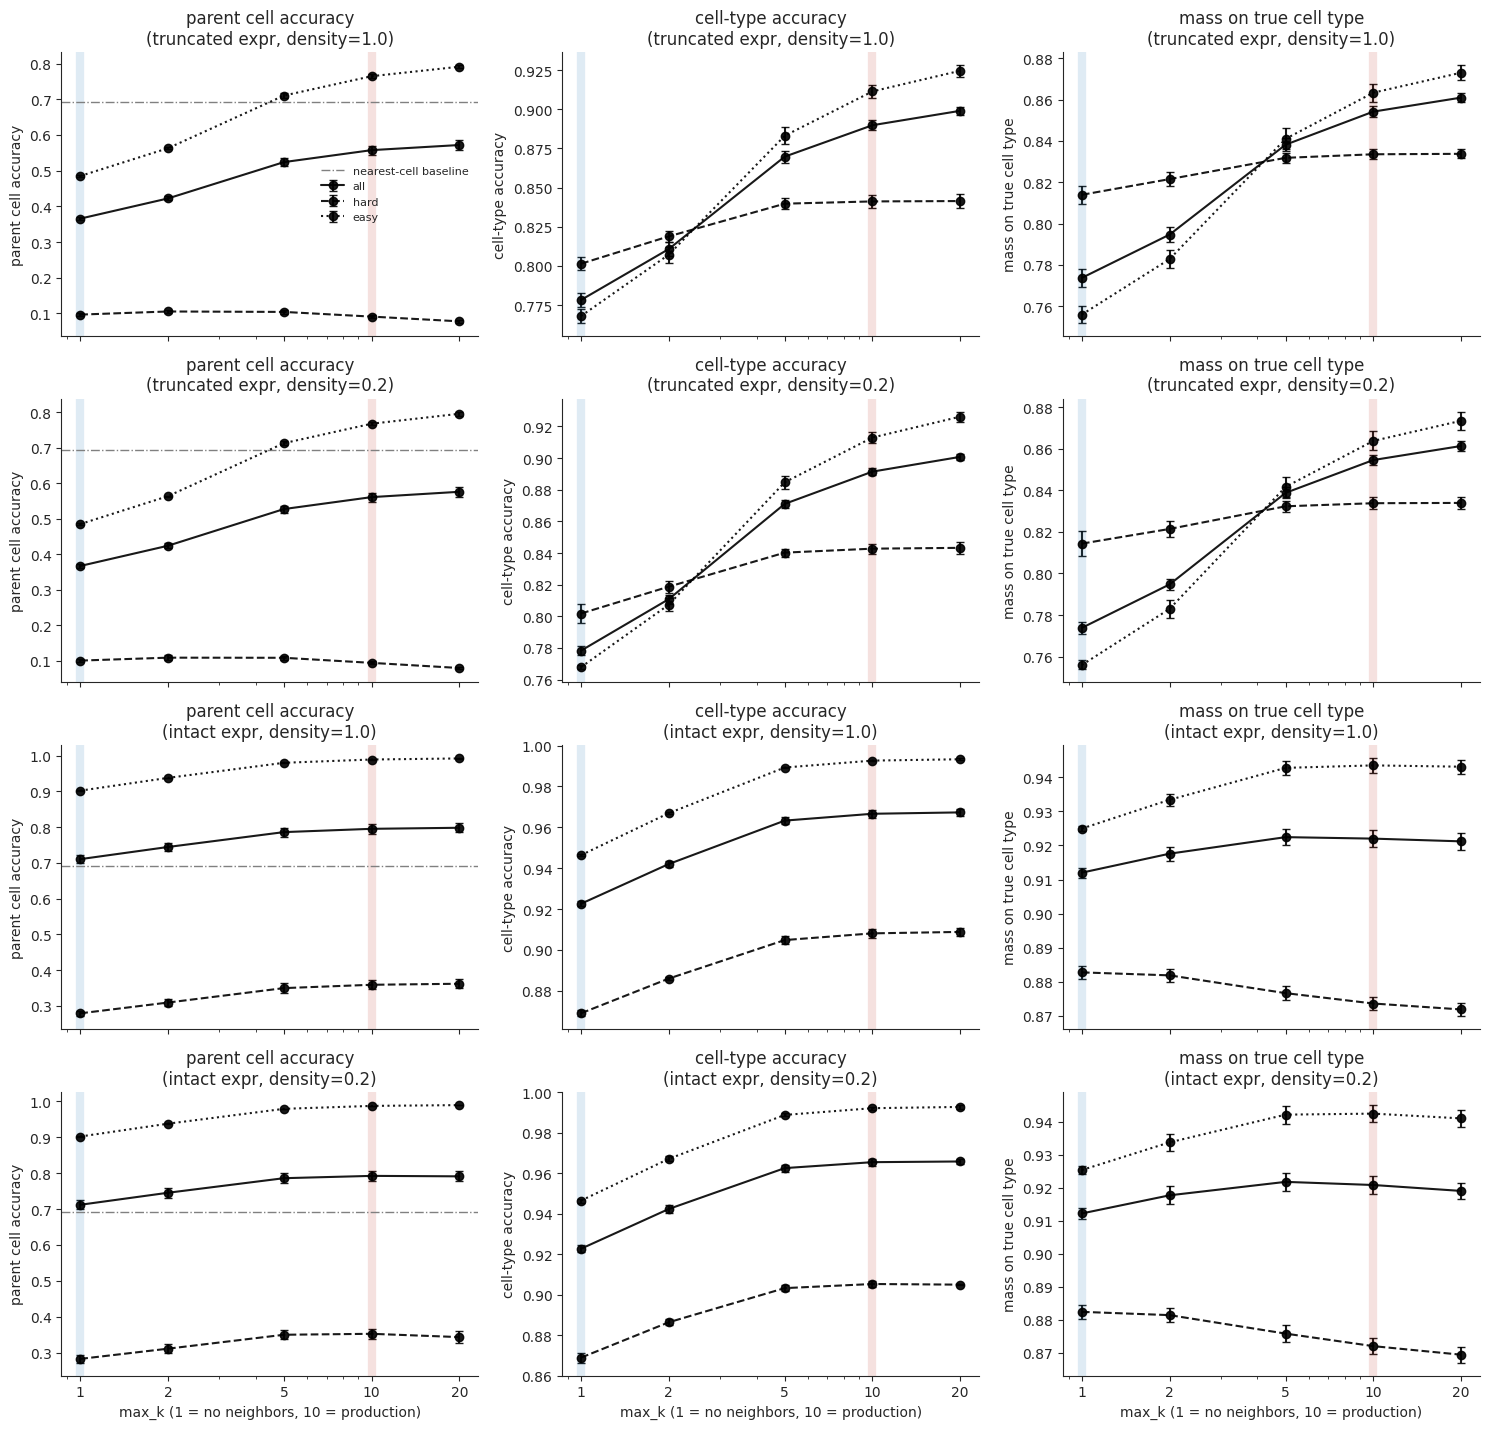

In [13]:
combos = [(em, d) for em in ['truncated', 'intact'] for d in sorted(bench['density'].unique(), reverse=True)]
fig, axes = plt.subplots(len(combos), 3, figsize=(15, 3.6 * len(combos)), sharex=True)
for i, (em, dens) in enumerate(combos):
    for j, (metric, lab) in enumerate([('parent_acc', 'parent cell accuracy'), ('type_acc', 'cell-type accuracy'), ('true_type_mass', 'mass on true cell type')]):
        ax = axes[i, j]
        for subset, ls in [('all', '-'), ('hard', '--'), ('easy', ':')]:
            d = acc[(acc.expr_mode == em) & (acc.density == dens) & (acc.subset == subset)].groupby('max_k')[metric].agg(['mean', 'std'])
            ax.errorbar(d.index, d['mean'], yerr=d['std'], fmt='o' + ls, color='k', capsize=3, label=subset, alpha=0.9)
        ax.axvline(1, color=MODE_COL['no_neighbors'], lw=6, alpha=0.15)
        ax.axvline(10, color=MODE_COL['with_neighbors'], lw=6, alpha=0.15)
        if metric == 'parent_acc':
            ax.axhline(nearest[dens], color='grey', lw=1, ls='-.', label='nearest-cell baseline')
        ax.set(title=f'{lab}\n({em} expr, density={dens})', ylabel=lab)
        ax.set_xscale('log'); ax.set_xticks(KS); ax.set_xticklabels(KS)
axes[0, 0].legend(frameon=False, fontsize=8)
for ax in axes[-1]: ax.set_xlabel('max_k (1 = no neighbors, 10 = production)')
sns.despine(); plt.tight_layout(); plt.savefig(saving_path / 'E_benchmark_maxk_sweep.pdf'); plt.show()

In [14]:
# Paired test per seed x density: production (k=10) vs no neighbors (k=1), and accuracy gain by adaptive-k bin
paired = acc[acc.subset == 'all'].pivot_table(index=['expr_mode', 'density', 'seed'], columns='max_k', values=['parent_acc', 'type_acc'])
gain = pd.DataFrame({'parent_acc gain (k10-k1), pp': (paired['parent_acc'][10] - paired['parent_acc'][1]) * 100,
                     'type_acc gain (k10-k1), pp': (paired['type_acc'][10] - paired['type_acc'][1]) * 100})
display(gain.round(2))

bench['k_bin'] = pd.cut(bench['k_prod'], [0, 1, 3, 6, 9, 10], labels=['1', '2-3', '4-6', '7-9', '10'])
byk = bench.groupby(['expr_mode', 'density', 'k_bin'], observed=True).apply(lambda g: pd.Series({
    'n': len(g),
    'parent acc k1': g['k1__parent_ok'].mean(), 'parent acc k10': g['k10__parent_ok'].mean(),
    'type acc k1': g['k1__type_ok'].mean(), 'type acc k10': g['k10__type_ok'].mean()}))
byk.to_csv(saving_path / 'E_benchmark_by_kbin.csv')
byk.round(3)

parent_acc gain (k10-k1), pp  \
expr_mode density seed                                 
intact    0.2     0                             7.99   
                  1                             7.90   
                  2                             8.25   
          1.0     0                             8.35   
                  1                             8.36   
                  2                             8.74   
truncated 0.2     0                            18.60   
                  1                            19.29   
                  2                            20.24   
          1.0     0                            18.37   
                  1                            18.98   
                  2                            20.23   

                        type_acc gain (k10-k1), pp  
expr_mode density seed                              
intact    0.2     0                           4.28  
                  1                           4.17  
                  2                           4.38  
          1.0     0                           4.34  
                  1                           4.35  
                  2                           4.52  
truncated 0.2     0                          11.17  
                  1                          11.07  
                  2                          11.72  
          1.0     0                          10.99  
                  1                          10.84  
                  2                          11.63

/tmp/ipykernel_1041342/3058995511.py:8: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  byk = bench.groupby(['expr_mode', 'density', 'k_bin'], observed=True).apply(lambda g: pd.Series({


n  parent acc k1  parent acc k10  type acc k1  \
expr_mode density k_bin                                                         
intact    0.2     1       24069.0          0.870           0.870        0.947   
                  2-3     26702.0          0.765           0.827        0.930   
                  4-6     42634.0          0.708           0.788        0.922   
                  7-9     51466.0          0.686           0.772        0.921   
                  10     129618.0          0.683           0.780        0.918   
          1.0     1      120399.0          0.870           0.870        0.948   
                  2-3    134735.0          0.763           0.828        0.929   
                  4-6    212847.0          0.709           0.792        0.922   
                  7-9    258546.0          0.683           0.775        0.920   
                  10     648838.0          0.681           0.783        0.918   
truncated 0.2     1       24069.0          0.356           0.356        0.608   
                  2-3     26702.0          0.371           0.558        0.724   
                  4-6     42634.0          0.360           0.590        0.773   
                  7-9     51466.0          0.359           0.581        0.800   
                  10     129618.0          0.373           0.581        0.814   
          1.0     1      120399.0          0.359           0.359        0.610   
                  2-3    134735.0          0.366           0.552        0.722   
                  4-6    212847.0          0.361           0.589        0.774   
                  7-9    258546.0          0.359           0.577        0.801   
                  10     648838.0          0.371           0.577        0.814   

                         type acc k10  
expr_mode density k_bin                
intact    0.2     1             0.947  
                  2-3           0.968  
                  4-6           0.969  
                  7-9           0.968  
                  10            0.966  
          1.0     1             0.948  
                  2-3           0.969  
                  4-6           0.970  
                  7-9           0.969  
                  10            0.968  
truncated 0.2     1             0.608  
                  2-3           0.846  
                  4-6           0.915  
                  7-9           0.932  
                  10            0.930  
          1.0     1             0.610  
                  2-3           0.844  
                  4-6           0.915  
                  7-9           0.930  
                  10            0.927

In [15]:
# Gene expressed in the true (truncated) cell? Without neighbors, a query whose gene vanished from its cell after hold-out cannot
# be assigned back to it; neighbors can rescue those cases.
t = bench[bench.expr_mode == 'truncated'].groupby(['density', 'gene_expr_in_true_after_holdout'])[['k1__parent_ok', 'k10__parent_ok']].mean()
t.columns = ['parent acc, no neighbors', 'parent acc, with neighbors']
t.round(3)

parent acc, no neighbors  \
density gene_expr_in_true_after_holdout                             
0.2     False                                               0.000   
        True                                                0.759   
1.0     False                                               0.000   
        True                                                0.757   

                                         parent acc, with neighbors  
density gene_expr_in_true_after_holdout                              
0.2     False                                                 0.455  
        True                                                  0.673  
1.0     False                                                 0.451  
        True                                                  0.672

## F. Qualitative: the same ROI under both modes
ROI as in notebook 5 (`roi=(4700, 5200, 1100, 1500)`). Intracellular transcripts are colored by their cell's type (faint);
extracellular transcripts by the top cell type of their source assignment (only `assignment score ≥ 0.2`, as in the paper figures).
The right panel highlights the transcripts whose top cell type changes.

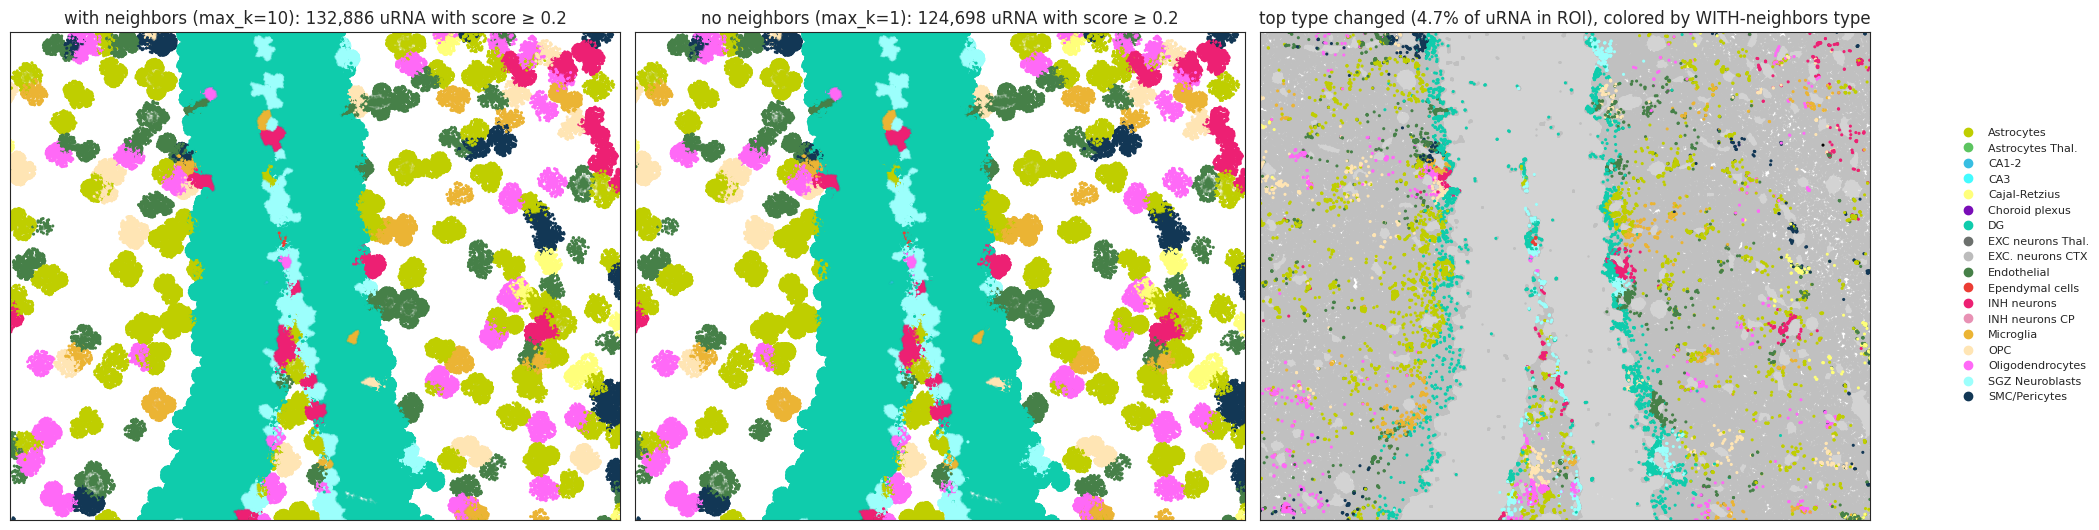

In [16]:
import pyarrow.dataset as pads
x0, x1, y0, y1 = 4700, 5200, 1100, 1500
dset = pads.dataset(str(data_dir / "data_annotated.zarr/points/transcripts/points.parquet"), format='parquet')
flt = (pads.field('x') >= x0) & (pads.field('x') <= x1) & (pads.field('y') >= y0) & (pads.field('y') <= y1)
roi_tx = dset.to_table(columns=['x', 'y', 'cell_id'], filter=flt).to_pandas()
cid2type = dict(zip(table.obs['cell_id'].astype(str), table.obs['cell_type'].astype(str)))
roi_tx['cell_type'] = roi_tx['cell_id'].astype(str).map(cid2type)
intra = roi_tx.dropna(subset=['cell_type'])
r = real[real.x.between(x0, x1) & real.y.between(y0, y1)].copy()

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, m in zip(axes[:2], MODES):
    ax.scatter(intra.x, intra.y, s=0.3, c=[ct_colors[t] for t in intra.cell_type], alpha=0.25, rasterized=True)
    rr = r[(r[f'{m}__score'] >= 0.2) & (r[f'{m}__type'] >= 0)]
    ax.scatter(rr.x, rr.y, s=1.5, c=[ct_colors[cell_types[t]] for t in rr[f'{m}__type']], rasterized=True)
    ax.set_title(f"{MODE_LABEL[m]}: {len(rr):,} uRNA with score ≥ 0.2")
ch = r[(r['with_neighbors__type'] != r['no_neighbors__type'])]
axes[2].scatter(intra.x, intra.y, s=0.3, c='lightgrey', rasterized=True)
axes[2].scatter(r.x, r.y, s=0.5, c='silver', rasterized=True)
axes[2].scatter(ch.x, ch.y, s=1.5, c=[ct_colors[cell_types[t]] if t >= 0 else 'k' for t in ch['with_neighbors__type']], rasterized=True)
axes[2].set_title(f'top type changed ({len(ch) / max(len(r), 1):.1%} of uRNA in ROI), colored by WITH-neighbors type')
for ax in axes:
    ax.set_aspect('equal'); ax.set_xlim(x0, x1); ax.set_ylim(y1, y0); ax.set_xticks([]); ax.set_yticks([])
handles = [plt.Line2D([], [], marker='o', ls='', color=ct_colors[t], label=t) for t in cell_types]
fig.legend(handles=handles, loc='center right', frameon=False, fontsize=8)
plt.tight_layout(rect=(0, 0, 0.9, 1)); plt.savefig(saving_path / 'F_roi_maps.pdf', dpi=300); plt.show()

## Summary

**Sanity check.** The `with_neighbors` mode reproduces the production λ=0.5 run exactly (parent agreement 1.000, max |score diff| 0).

**Real data (8.39 M extracellular transcripts).**
* 70% of uRNA sit at/below the ambient floor (k=1), so neighbors are only used for the remaining **30%**; for k=1 transcripts both modes agree by construction (99.98%).
* Among transcripts that do use neighbors, **~36% change parent cell** and **~19% change top cell type**; overall 89.6% keep the same parent and 94.2% the same top cell type. Assignment rate is essentially unchanged (99.6% vs 99.4%).
* With neighbors, assignments are **more confident** (median score 0.256 vs 0.212; 59% vs 51% of uRNA above the `min_score=0.2` threshold used in the figures), cell-type mass is more concentrated, and the source is **closer** (median 4.8 vs 6.6 µm).
* Trade-off: with neighbors the parent expresses the transcript's own gene in 69% of cases (100% by construction without), and the predicted type is slightly less often a top-3 expresser of that gene (0.36 vs 0.39). Neighbors trade "gene-level" plausibility for "neighborhood-level" coherence.
* **Downstream conclusions are unchanged**: per-cell `urna_source_score` Spearman 0.997, per-cell-type ranking Spearman 0.998 (normalized 0.994), median per-gene type-attribution cosine 0.97. Changes concentrate in a small set of sparsely detected genes (e.g. Tdgf1, Esrrb, Nmu, Hcrt), i.e. genes with little intracellular expression to anchor a gene-only match.

**Ground-truth benchmark (peripheral hold-out, ~0.45 M queries per seed, 3 seeds).**
* Neighbors improve recovery in every setting, consistently across seeds (sd ≈ 1 pp):
  * *truncated expression* (realistic): parent accuracy 0.37 → **0.56** (+19 pp), cell-type accuracy 0.78 → **0.89** (+11 pp).
  * *intact expression* (pure spatial-context effect): parent 0.71 → **0.79** (+8 pp), cell type 0.92 → **0.97** (+4 pp).
* The gain saturates around max_k = 5-10 (max_k=20 adds ≤1.5 pp), supporting the production choice of 10. The gain is the same at full and 20% ring density.
* Gains come from transcripts whose own gene alone is uninformative: without neighbors, a transcript whose gene isn't (or is no longer) detected inside its true cell can never be assigned to it (0% vs 45% with neighbors); when the gene is present, the gene-only match is slightly better at the *parent* level (0.76 vs 0.67) but neighbors still win at the *cell-type* level.
* Caveat: held-out transcripts sit at the truncated cell edge, which favors a trivial nearest-cell assignment (parent acc 0.69). The production score beats it only when expression is intact; at the cell-type level (the quantity used for the composition / communication analyses) neighbors give the best recovery in all settings.

**Bottom line.** Adding the neighborhood changes ~10% of individual parent assignments and leaves all per-cell and per-cell-type results of the paper essentially unchanged. It measurably improves source recovery where it matters (+11 pp cell-type accuracy in the realistic benchmark, +4 pp even when expression is complete), and it makes assignments more confident and spatially tighter.


In [17]:
print('Fraction of uRNA that use neighbors (k_prod>1):', f"{(real['k_prod'] > 1).mean():.3f}")
print('Assignment rate  with / without:', f"{real['with_neighbors__assigned'].mean():.3f} / {real['no_neighbors__assigned'].mean():.3f}")
print('Same parent (both assigned):', f"{real.loc[both, 'same_parent'].mean():.3f}", '| same top type:', f"{real.loc[both, 'same_type'].mean():.3f}")
print('Per-cell score Spearman:', f"{spearmanr(a, b)[0]:.3f}", '| cell-type ranking Spearman:', f"{rho_rank:.3f}")
print('Benchmark (mean over seeds):')
display(acc[acc.max_k.isin([1, 10])].groupby(['expr_mode', 'density', 'subset', 'max_k'])[['parent_acc', 'type_acc']].mean().unstack('max_k').round(3))
print('Nearest-cell baseline parent acc:', nearest.round(3).to_dict())

Fraction of uRNA that use neighbors (k_prod>1): 0.299
Assignment rate  with / without: 0.996 / 0.994
Same parent (both assigned): 0.896 | same top type: 0.942
Per-cell score Spearman: 0.997 | cell-type ranking Spearman: 0.998
Benchmark (mean over seeds):


parent_acc        type_acc       
max_k                            1      10       1      10
expr_mode density subset                                  
intact    0.2     all         0.712  0.792    0.923  0.965
                  easy        0.902  0.987    0.946  0.992
                  hard        0.283  0.353    0.869  0.905
          1.0     all         0.710  0.795    0.923  0.967
                  easy        0.902  0.989    0.946  0.993
                  hard        0.279  0.359    0.869  0.908
truncated 0.2     all         0.367  0.561    0.778  0.891
                  easy        0.485  0.767    0.768  0.913
                  hard        0.101  0.094    0.802  0.843
          1.0     all         0.366  0.558    0.778  0.890
                  easy        0.485  0.765    0.768  0.911
                  hard        0.097  0.091    0.801  0.841

Nearest-cell baseline parent acc: {0.2: 0.693, 1.0: 0.692}
